# 05 · Two helper classifiers that look at zoomed-in tiles

**Problem.** The whole-photo embedding summarises the whole scene. A small detail that decides the label — trash spilling
over one bin, one untied bag in a street scene — barely changes it.

**Idea.** Cut each photo into 13 overlapping tiles (a 2 × 2 and a 3 × 3 grid) and let two small classifiers, each trained
on its own external data, score every tile. The highest tile score (and the mean of the two highest) are added to the
photo's features:

| helper | trained on | question | numbers added |
|---|---|---|---|
| overflow | CDCM: 300 clean + 300 dirty street containers (Kaggle, CC BY 4.0) | is this part an overflowing bin? | 4 (2 image models × max / top-2) |
| bag | the 12 licensed bag photos (7 tied, 5 open), photo + mirror + 13 tiles each | is this part an open bag? | 2 (max / top-2) |

The helpers never see the competition labels, so they can be computed once for all photos without leaking answers;
in each CV fold only the final classifier is retrained. Final input per photo: 2048 (DINOv2) + 4 + 2 = 2054 numbers.

In [1]:
import numpy as np, pandas as pd
import common as c
pd.set_option('display.width', 200)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

The 13 tiles of one photo (#100, Trash Incomplete):

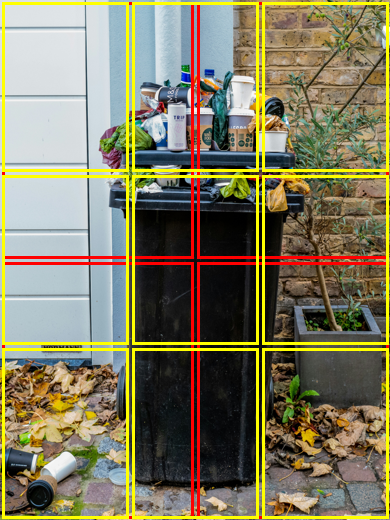

In [2]:
from PIL import ImageDraw, ImageOps, Image
im = ImageOps.exif_transpose(Image.open(c.image_path(100))).convert("RGB"); im.thumbnail((520, 520))
w, h = im.size; d = ImageDraw.Draw(im)
for k, (x0, y0, x1, y1) in enumerate(c.TILE_BOXES):
    d.rectangle([x0 * w + 2, y0 * h + 2, x1 * w - 2, y1 * h - 2], outline="red" if k < 4 else "yellow", width=3)
im

## Helper 1: overflowing bins (CDCM)

CDCM = *Clean-Dirty Containers in Montevideo* (Rodrigo Laguna, Kaggle, CC BY 4.0). Only its smartphone photos are used:
the other sources are confounded with the label (one is almost all dirty, Street View mostly clean), so a classifier
could learn the source instead of the dirt. 400 per class were sampled and encoded once (`features/cdcm_*.npz`).

In [3]:
ids_all = sorted(set(c.training_set(list(set(c.external().group))).id) | set(c.competition()[1].id))
over = {}
for b in ("dinov2_l", "siglip_so400m"):
    z = np.load(c.FEAT / f"cdcm_{b}.npz", allow_pickle=True)
    tr, va = z["split"] == "train", z["split"] == "test"
    m = LogisticRegression(C=1, max_iter=5000).fit(z["feats"][tr], z["y"][tr])
    p = m.predict_proba(z["feats"][va])[:, 1]
    print(f"{b}: CDCM held-out accuracy {accuracy_score(z['y'][va], p > .5):.3f}, AUC {roc_auc_score(z['y'][va], p):.3f}")
    helper = LogisticRegression(C=1, max_iter=5000).fit(z["feats"], z["y"])      # refit on all CDCM photos
    T = c.tile_embeddings(ids_all, b)                                            # cached; new photos are encoded
    s = helper.predict_proba(T.reshape(-1, T.shape[-1]))[:, 1].reshape(len(ids_all), -1)
    over[f"{b}_tiles"], over[f"{b}_tile_max"], over[f"{b}_tile_top2"] = s, s.max(1), np.sort(s, 1)[:, -2:].mean(1)
np.savez(c.FEAT / "overflow_tiles.npz", ids=np.array(ids_all), **over)

dinov2_l: CDCM held-out accuracy 0.895, AUC 0.941
siglip_so400m: CDCM held-out accuracy 0.935, AUC 0.987


## Helper 2: open vs tied bags

In [4]:
TIED, OPEN = [901, 902, 903, 904, 905, 907, 910], [951, 952, 953, 954, 955]
z, pos = c._load("dinov2_l")
T = c.tile_embeddings(TIED + OPEN)
Xh, yh = [], []
for k, i in enumerate(TIED + OPEN):
    rows = [c.unit(z["img"][pos[i]]), c.unit(z["img_flip"][pos[i]])] + list(T[k])
    Xh += rows; yh += [int(i in OPEN)] * len(rows)
bag = LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced").fit(np.array(Xh), np.array(yh))
T = c.tile_embeddings(ids_all)
s = bag.predict_proba(T.reshape(-1, T.shape[-1]))[:, 1].reshape(len(ids_all), -1)
np.savez(c.FEAT / "bag_learned.npz", ids=np.array(ids_all), bag_open_tiles=s, bag_open_max=s.max(1),
         bag_open_top2=np.sort(s, 1)[:, -2:].mean(1))
print(len(yh), "helper training rows")

180 helper training rows


How well each helper alone separates *Trash Incomplete* from *Trash Complete* on the 33 competition trash photos
(AUC: 1 = perfect, 0.5 = chance; no training on these photos):

In [5]:
train, _ = c.competition()
t = train[train.label.str.startswith("Taking")]
inc = t.label.str.endswith("Incomplete").values
pd.Series({"overflow helper (DINOv2 tiles)": roc_auc_score(inc, c.overflow_inputs(t.id)[:, 0]),
           "bag helper": roc_auc_score(inc, c.bag_inputs(t.id)[:, 0])}, name="AUC").round(3)

overflow helper (DINOv2 tiles)    0.696
bag helper                        0.842
Name: AUC, dtype: float64

## What the helpers add to the final training set

In [6]:
df = c.training_set(final=True)
E, O, B = c.embed(df.id), c.overflow_inputs(df.id), c.bag_inputs(df.id)
res, wrong = [], {}
for name, X in (("DINOv2 only", E), ("+ overflow helper", np.hstack([E, O])), ("+ overflow + bag helper (final)", np.hstack([E, O, B]))):
    r, P = c.cross_validate(df, X, list(c.MODELS), name=name)
    res.append(r); wrong[name] = c.wrong_counts(df, P["RBF SVM"])
pd.concat(res).pivot_table(index="experiment", columns="model", values="CV macro F1", sort=False).round(3)

model,logistic regression,RBF SVM,extra trees,neural net (MLP)
experiment,,,,
DINOv2 only,0.872,0.882,0.860,0.874
+ overflow helper,0.892,0.905,0.869,0.859
+ overflow + bag helper (final),0.895,0.912,0.863,0.847


In [7]:
pd.DataFrame(wrong).fillna(0).astype(int)

,DINOv2 only,+ overflow helper,+ overflow + bag helper (final)
#13,10,3,1
#26,10,10,10
#31,9,10,10
#46,1,0,0
#47,1,1,1
#48,1,1,1
#53,1,0,0
#60,10,10,10
#77,6,10,10
#99,8,0,0


**Result.** Both helpers only change the trash classes, as intended. With the RBF SVM, DINOv2 alone scores 0.882; the
overflow helper raises it to 0.905 (fixes overflowing-bin photos #100 and #99) and the bag helper to 0.912 (fixes
#13). Logistic regression gains too (0.872 → 0.895); extra trees and the neural net do not gain.